# 3. Sobel and Canny Edge Detection

## Table of Contents
1. [Libraries](#libraries)
2. [Sobel Edge Detection](#sobel)
3. [Canny Edge Detection](#canny)

## Importing Libraries <a class="anchor" id="libraries" ></a>

In [1]:
import cv2
import skimage
import numpy as np
from scipy import ndimage
from skimage import exposure
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.ndimage.filters import convolve
from scipy.ndimage.filters import gaussian_filter as gauss
from scipy.ndimage.filters import median_filter as med
import time


/tmp/ipykernel_3638878/1944948776.py:9: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import convolve
/tmp/ipykernel_3638878/1944948776.py:10: DeprecationWarning: Please import `gaussian_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import gaussian_filter as gauss
/tmp/ipykernel_3638878/1944948776.py:11: DeprecationWarning: Please import `median_filter` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import median_filter as med


## Sobel Edge Detection <a class="anchor" id="sobel" ></a>

As a first step in extracting features, you will apply the Sobel edge detection algorithm. This finds regions of the image with large gradient values in multiple directions. Regions with high omnidirectional gradient are likely to be edges or transitions in the pixel values. 

The code in the cell below applies the Sobel algorithm to the median filtered image, using these steps:

1. Convert the color image to grayscale for the gradient calculation since it is two dimensional.
2. Compute the gradient in the x and y (horizontal and vertical) directions. 
3. Compute the magnitude of the gradient.
4. Normalize the gradient values. 

In [2]:
def edge_sobel(image):
    from scipy import ndimage
    import skimage.color as sc
    import numpy as np
    image = sc.rgb2gray(image) # Convert color image to gray scale
    dx = ndimage.sobel(image, 1)  # horizontal derivative
    dy = ndimage.sobel(image, 0)  # vertical derivative
    mag = np.hypot(dx, dy)  # magnitude
    mag *= 255.0 / np.amax(mag)  # normalize (Q&D)
    mag = mag.astype(np.uint8)
    return mag

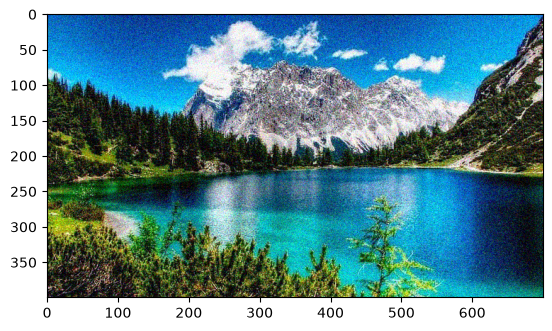

In [3]:
original_image = np.load('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/img.npy')

img = skimage.util.random_noise(original_image)
plt.imshow(img)

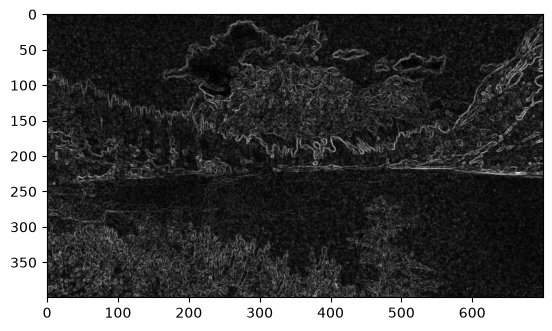

In [4]:
img_med = med(img, size=2)
img_edge = edge_sobel(img_med)
plt.imshow(img_edge, cmap="gray")

Now let's try with the more blurred gaussian filtered image.

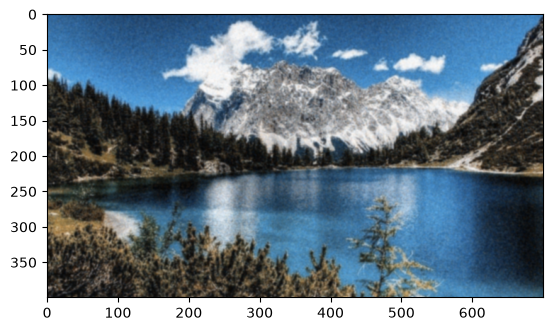

In [5]:
img_gauss = gauss(img, sigma=1)   
plt.imshow(img_gauss)

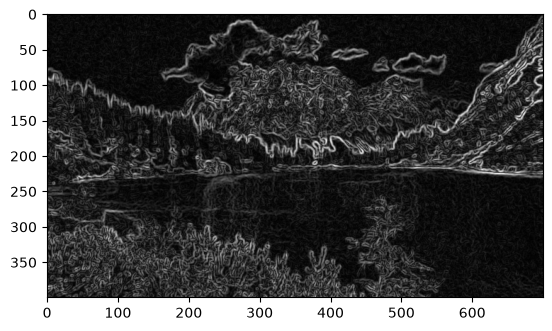

In [6]:
img_edge = edge_sobel(img_gauss)
plt.imshow(img_edge, cmap="gray")

## Canny Edge Detection <a class="anchor" id="canny" ></a>

Steps:
1. Noise Reduction
2. Gradient Calculation
3. Non-maximum Supression
4. Double Threshold
5. Edge Tracking by Hysteresis

**Pre-requisite:** Convert the image to grayscale before algorithm.

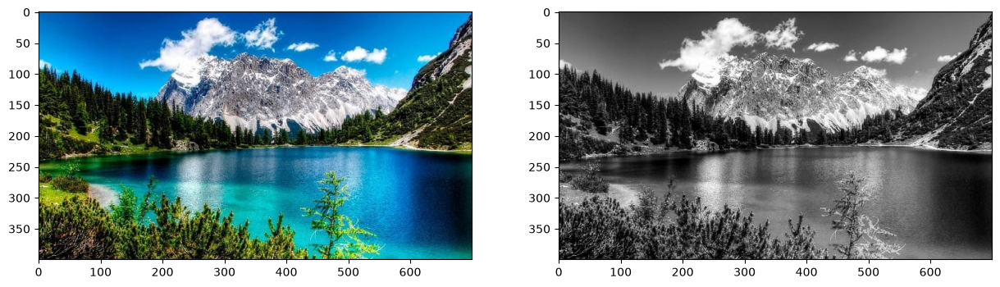

In [7]:
img = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/image.jpg')

img_color = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_color)
plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap="gray")

### 1. Noise Reduction
Edge detection are highly sensitive to image noise due to the derivatives behind the algorithm.

We can apply a Gaussian Kernel, the size of the kernel depends on the expected blurring effect. The smaller the less blurring effect.

Equation for Gaussian Kernel of size $(2k+1) \times (2k+1)$

$$
H_{i, j} = \frac{1}{2\pi\sigma^2}exp(-\frac{(i-(k+1))^2 + (j-(k+1))^2}{2\sigma^2}); 1\leq i, j \leq (2k+1)
$$

In [8]:
def gaussian_kernel(size, sigma=1):
    size = int(size) // 2
    x, y = np.mgrid[-size:size+1, -size:size+1]
    normal = 1 / (2.0 * np.pi * sigma**2)
    g =  np.exp(-((x**2 + y**2) / (2.0*sigma**2))) * normal
    return g

### 1.1 Sigma Parameter $\sigma$

In [9]:
# Change this parameter
sigma = 10 # 1, 3, 5, 10, 20, ...

### 1.2 Kernel Size Parameter

In [10]:
kernel_size = 3

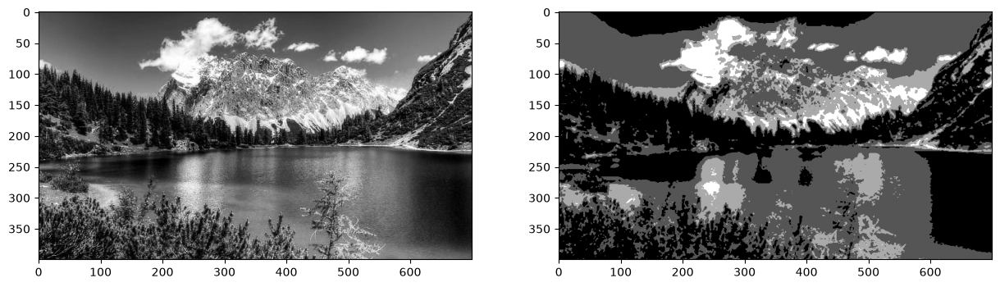

In [11]:
img_gaussian = convolve(img_gray, gaussian_kernel(kernel_size, sigma))

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(img_gaussian, cmap="gray")

### 2. Gradient Calculation

Edges correspond to a change of pixels intensity. 

To detect it, the easiest way is to apply filters that highlight this intensity change in both directions: 
- horizontal $(x)$ 
- and vertical $(y)$

It can be implemented by convoling $I$ with *Sobel kernels* $Kx$ and $Ky$

$$
K_x = \begin{bmatrix}
-1 & 0 & 1\\
-2 & 0 & 2\\
-1 & 0 & 1
\end{bmatrix}, K_y = \begin{bmatrix}
1 & 2& 1\\
0 & 0 & 0\\
-1 & -2 & -1
\end{bmatrix}
$$

Then, the magnitude $G$ and the slope $\theta$ of the gradient are calculated as follow:

$$
|G| = \sqrt{I_x^2 + I_y^2},
\theta(x, y) = arctan(\frac{I_y}{I_x})
$$

In [12]:
def sobel_filters(img):
    Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
    Ky = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]], np.float32)
    
    Ix = ndimage.filters.convolve(img, Kx)
    Iy = ndimage.filters.convolve(img, Ky)
    
    G = np.hypot(Ix, Iy)
    G = G / G.max() * 255
    theta = np.arctan2(Iy, Ix)
    
    return (G, theta)

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


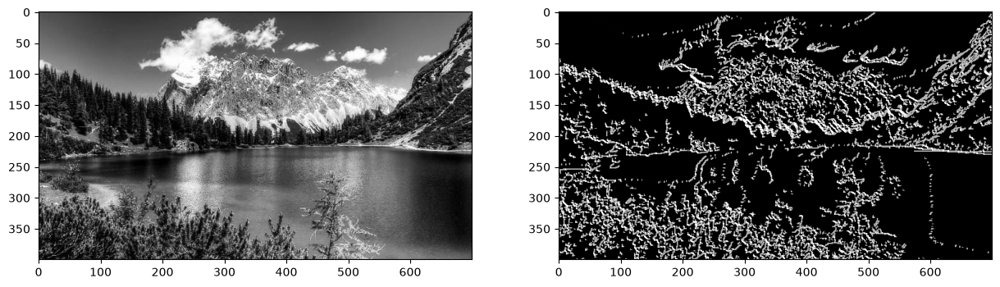

In [13]:
G, theta = sobel_filters(img_gaussian)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(G, cmap="gray")

### 3. Non-Maximum supression

1. Create a matrix initialized to 0 of the same size of the original gradient intensity matrix
2. Identify the edge direction based on the angle value from the angle matrix
3. Check if the pixel in the same direction has a higher intensity than the pixel that is currently processed
4. Return the image processed with the non-max suppression algorithm.

In [14]:
def non_max_suppression(img, D):
    M, N = img.shape
    Z = np.zeros((M,N), dtype=np.int32)
    angle = D * 180. / np.pi
    angle[angle < 0] += 180

    
    for i in range(1,M-1):
        for j in range(1,N-1):
            try:
                q = 255
                r = 255
                
               #angle 0
                if (0 <= angle[i,j] < 22.5) or (157.5 <= angle[i,j] <= 180):
                    q = img[i, j+1]
                    r = img[i, j-1]
                #angle 45
                elif (22.5 <= angle[i,j] < 67.5):
                    q = img[i+1, j-1]
                    r = img[i-1, j+1]
                #angle 90
                elif (67.5 <= angle[i,j] < 112.5):
                    q = img[i+1, j]
                    r = img[i-1, j]
                #angle 135
                elif (112.5 <= angle[i,j] < 157.5):
                    q = img[i-1, j-1]
                    r = img[i+1, j+1]

                if (img[i,j] >= q) and (img[i,j] >= r):
                    Z[i,j] = img[i,j]
                else:
                    Z[i,j] = 0

            except IndexError as e:
                pass
    
    return Z

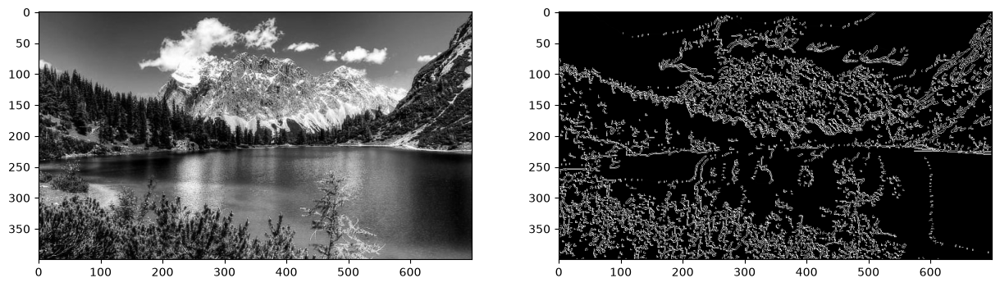

In [15]:
img_nonmax = non_max_suppression(G, theta)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(img_nonmax, cmap="gray")

### 4. Double threshold

- Strong pixels are pixels that have an intensity so high that we are sure they contribute to the final edge.
- Weak pixels are pixels that have an intensity value that is not enough to be considered as strong ones, but yet not small enough to be considered as non-relevant for the edge detection.
- Other pixels are considered as non-relevant for the edge.

In [16]:
def threshold(img, lowThresholdRatio=0.05, highThresholdRatio=0.09):
    
    highThreshold = img.max() * highThresholdRatio;
    lowThreshold = highThreshold * lowThresholdRatio;
    
    M, N = img.shape
    res = np.zeros((M,N), dtype=np.int32)
    
    weak = np.int32(25)
    strong = np.int32(255)
    
    strong_i, strong_j = np.where(img >= highThreshold)
    zeros_i, zeros_j = np.where(img < lowThreshold)
    
    weak_i, weak_j = np.where((img <= highThreshold) & (img >= lowThreshold))
    
    res[strong_i, strong_j] = strong
    res[weak_i, weak_j] = weak
    
    return (res)

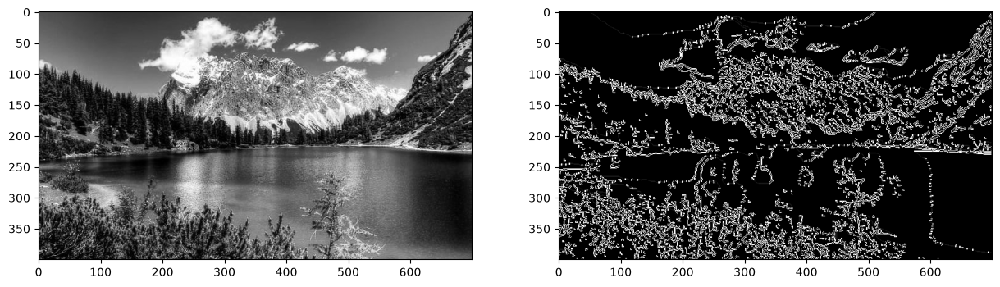

In [17]:
img_threshold = threshold(img_nonmax)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(img_threshold, cmap="gray")

### 5. Edge Tracking by Hysteresis

The hysteresis consists of transforming weak pixels into strong ones, if and only if at least one of the pixels around the one being processed is a strong one

In [18]:
def hysteresis(img, weak = 75, strong=255):
    M, N = img.shape  
    for i in range(1, M-1):
        for j in range(1, N-1):
            if (img[i,j] == weak):
                try:
                    if ((img[i+1, j-1] == strong) or (img[i+1, j] == strong) or (img[i+1, j+1] == strong)
                        or (img[i, j-1] == strong) or (img[i, j+1] == strong)
                        or (img[i-1, j-1] == strong) or (img[i-1, j] == strong) or (img[i-1, j+1] == strong)):
                        img[i, j] = strong
                    else:
                        img[i, j] = 0
                except IndexError as e:
                    pass
    return img

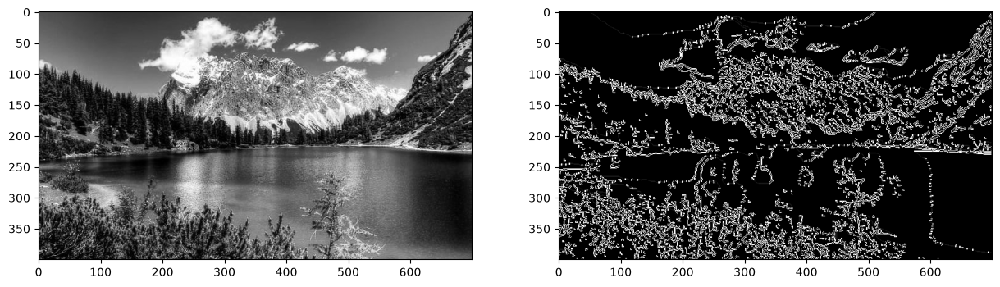

In [19]:
img_final = hysteresis(img_threshold)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(img_final, cmap="gray")

### Start working from here

## Aplicación a) — Canny desde cero en imagen industrial (fábrica) con 4 valores de σ

**Justificación (dominio BSKLab):** La imagen de la planta industrial (fila de prensas de estampado) es el caso de uso real de la inspección por visión: los bordes de la maquinaria son la materia prima de detección de objetos, alineación de cámaras y calibración. Aquí replicamos el pipeline completo del notebook (Gaussiano → Sobel → NMS → doble umbral → hystéresis) sobre `data/semana6/factory_a.jpg` con **σ ∈ {1, 3, 5, 10, 20}** y kernel fijo (3×3).

Recuerda lo visto en clase (Módulo 3.1, p.20): **σ grande → líneas gruesas / escala grande; σ pequeño → líneas finas / detalle fino**.

factory_gray: (563, 1000)


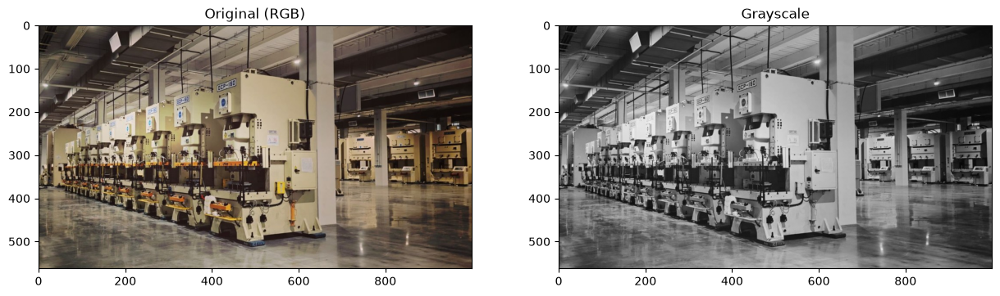

In [20]:
factory = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana6/factory_a.jpg')
factory_color = cv2.cvtColor(factory, cv2.COLOR_BGR2RGB)
factory_gray  = cv2.cvtColor(factory, cv2.COLOR_BGR2GRAY)
print('factory_gray:', factory_gray.shape)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1); plt.imshow(factory_color); plt.title('Original (RGB)')
plt.subplot(1, 2, 2); plt.imshow(factory_gray, cmap='gray'); plt.title('Grayscale')
plt.show()

### a.1) Pipeline completo para cada σ

Mismo código del notebook (misma `gaussian_kernel`, `sobel_filters`, `non_max_suppression`, `threshold`, `hysteresis`); solo cambia `sigma`.

In [21]:
def canny_from_scratch(gray, sigma, kernel_size=3,
                       lowRatio=0.05, highRatio=0.09):
    """Pipeline Canny completo (5 pasos) - mismo codigo que el template."""
    # 1. Noise reduction (Gaussian)
    img_gaussian = convolve(gray, gaussian_kernel(kernel_size, sigma))
    # 2. Gradient
    G, theta = sobel_filters(img_gaussian)
    # 3. Non-maximum suppression
    img_nonmax = non_max_suppression(G, theta)
    # 4. Double threshold
    img_thr = threshold(img_nonmax, lowThresholdRatio=lowRatio,
                        highThresholdRatio=highRatio)
    # 5. Hysteresis
    img_final = hysteresis(img_thr)
    return img_gaussian, G, img_nonmax, img_thr, img_final

sigmas = [1, 3, 5, 10, 20]
results = {}
for s in sigmas:
    t0 = time.time()
    results[s] = canny_from_scratch(factory_gray, s)
    edge_px = (results[s][4] == 255).sum()
    print(f'sigma={s:>2}: tiempo {time.time()-t0:.2f}s, pixeles de borde={edge_px}')

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


sigma= 1: tiempo 0.88s, pixeles de borde=176870


sigma= 3: tiempo 0.79s, pixeles de borde=152454


sigma= 5: tiempo 0.79s, pixeles de borde=122192


sigma=10: tiempo 0.71s, pixeles de borde=63047


/tmp/ipykernel_3638878/65442114.py:9: RuntimeWarning: invalid value encountered in divide
  G = G / G.max() * 255


sigma=20: tiempo 0.61s, pixeles de borde=0


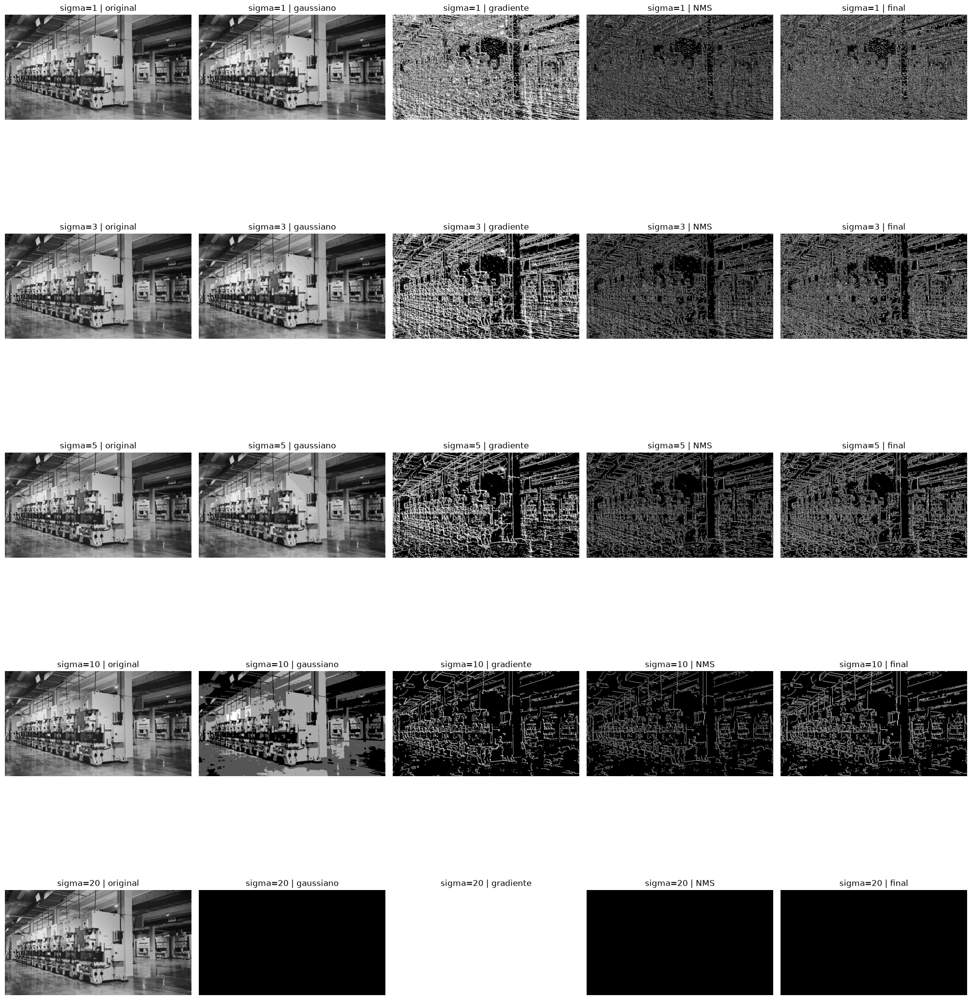

In [22]:
plt.figure(figsize=(20, 24))
for row, s in enumerate(sigmas):
    _, G, nm, thr, fin = results[s]
    plt.subplot(5, 5, row*5+1); plt.imshow(factory_gray, cmap='gray'); plt.title(f'sigma={s} | original'); plt.axis('off')
    plt.subplot(5, 5, row*5+2); plt.imshow(results[s][0], cmap='gray'); plt.title(f'sigma={s} | gaussiano'); plt.axis('off')
    plt.subplot(5, 5, row*5+3); plt.imshow(G, cmap='gray'); plt.title(f'sigma={s} | gradiente'); plt.axis('off')
    plt.subplot(5, 5, row*5+4); plt.imshow(nm, cmap='gray'); plt.title(f'sigma={s} | NMS'); plt.axis('off')
    plt.subplot(5, 5, row*5+5); plt.imshow(fin, cmap='gray'); plt.title(f'sigma={s} | final'); plt.axis('off')
plt.tight_layout()
plt.show()

### a.2) Zoom en la misma región para comparar σ

Vista ampliada de una zona con estructura fina (parte superior de la maquinaria) para apreciar con detalle cómo σ controla qué líneas sobreviven.

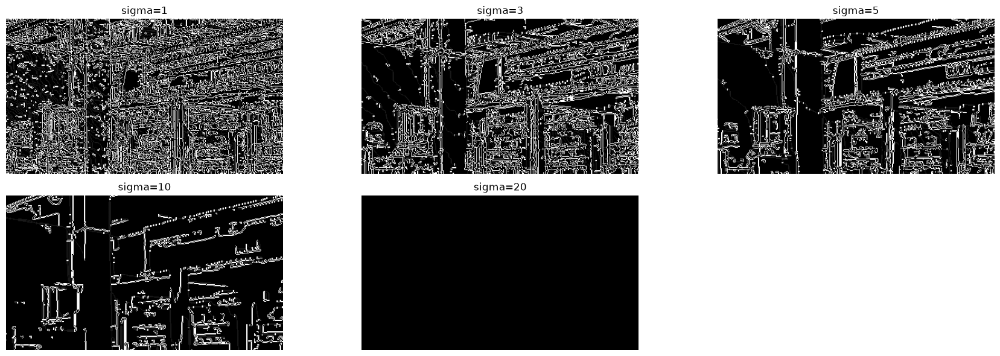

In [23]:
r0, c0, r1, c1 = 80, 520, 320, 950  # recorte de la fila de prensas

plt.figure(figsize=(18, 6))
for i, s in enumerate(sigmas):
    fin = results[s][4][r0:r1, c0:c1]
    plt.subplot(2, 3, i+1)
    plt.imshow(fin, cmap='gray')
    plt.title(f'sigma={s}')
    plt.axis('off')
plt.tight_layout()
plt.show()

### a.3) Hallazgos a)

Véanse las conclusiones al final del notebook (sección e).

## Aplicación b) — Canny con y sin remoción de ruido

**Justificación:** el paso 1 de Canny es la reducción de ruido con Gaussiano (Módulo 3.1, pp.17, 20). Para entenderlo, comparamos en la **misma imagen** (fábrica, σ fijo = 3):

- **Sin remoción de ruido:** se calcula el gradiente directamente sobre la imagen en gris (se omite el paso 1).
- **Con remoción de ruido:** pipeline estándar (Gaussiano σ=3 → gradiente → …).

Además añadimos el caso extremo: **ruido artificial sal y pimienta** (5%) + suavizado, para ver cómo el Gaussiano protege al detector.

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


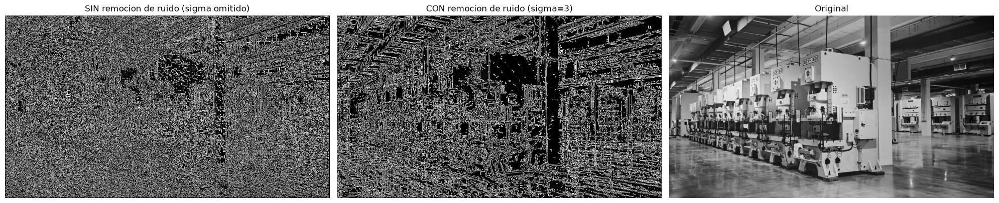

pixeles de borde  sin suavizado: 192395
pixeles de borde  con suavizado: 152454
razon: 1.26x


In [24]:
def canny_no_denoise(gray, lowRatio=0.05, highRatio=0.09):
    """Canny SIN el paso 1: gradiente directo sobre la imagen (sin suavizado)."""
    G, theta = sobel_filters(gray)          # salto el paso 1 (Gaussian)
    img_nonmax = non_max_suppression(G, theta)
    img_thr = threshold(img_nonmax, lowThresholdRatio=lowRatio,
                        highThresholdRatio=highRatio)
    img_final = hysteresis(img_thr)
    return G, img_nonmax, img_final

G_nd, nm_nd, fin_nd = canny_no_denoise(factory_gray)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
axes[0].imshow(fin_nd, cmap='gray'); axes[0].set_title('SIN remocion de ruido (sigma omitido)'); axes[0].axis('off')
axes[1].imshow(results[3][4], cmap='gray'); axes[1].set_title('CON remocion de ruido (sigma=3)'); axes[1].axis('off')
axes[2].imshow(factory_gray, cmap='gray'); axes[2].set_title('Original'); axes[2].axis('off')
plt.tight_layout()
plt.show()

edge_no  = (fin_nd == 255).sum()
edge_yes = (results[3][4] == 255).sum()
print(f'pixeles de borde  sin suavizado: {edge_no}')
print(f'pixeles de borde  con suavizado: {edge_yes}')
print(f'razon: {edge_no/edge_yes:.2f}x')

### b.1) Caso extremo: ruido artificial + suavizado

Añadimos ruido salt-and-pepper (5%) — el tipo de ruido que más castiga a los operadores de derivada — y comparamos detectar sobre la imagen ruidosa vs. después de suavizar con Gaussiano.

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


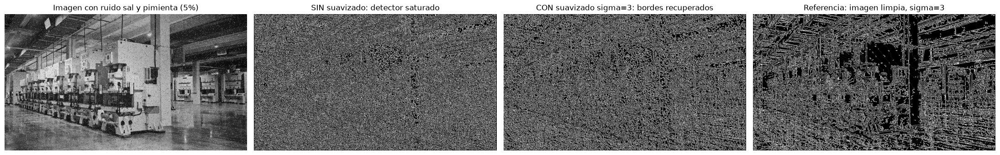

pixeles de borde con ruido, sin suavizado: 200501
pixeles de borde con ruido, con suavizado: 189986


In [25]:
h_f, w_f = factory_gray.shape
noise_img = factory_gray.copy()
n_pixels = int(0.05 * h_f * w_f)
rng = np.random.default_rng(42)
idx = rng.integers(0, h_f*w_f, n_pixels)
noise_img.flat[idx] = rng.choice([0, 255], n_pixels)

# Canny sobre la ruidosa (SIN suavizado adicional)
G_r, nm_r, fin_r = canny_no_denoise(noise_img)
# Canny sobre la ruidosa CON suavizado sigma=3
_, _, _, _, fin_r_smooth = canny_from_scratch(noise_img, 3)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
axes[0].imshow(noise_img, cmap='gray'); axes[0].set_title('Imagen con ruido sal y pimienta (5%)'); axes[0].axis('off')
axes[1].imshow(fin_r, cmap='gray');    axes[1].set_title('SIN suavizado: detector saturado'); axes[1].axis('off')
axes[2].imshow(fin_r_smooth, cmap='gray'); axes[2].set_title('CON suavizado sigma=3: bordes recuperados'); axes[2].axis('off')
axes[3].imshow(results[3][4], cmap='gray'); axes[3].set_title('Referencia: imagen limpia, sigma=3'); axes[3].axis('off')
plt.tight_layout()
plt.show()

print('pixeles de borde con ruido, sin suavizado:', (fin_r==255).sum())
print('pixeles de borde con ruido, con suavizado:', (fin_r_smooth==255).sum())

### b.2) Hallazgos b)

Véanse las conclusiones al final del notebook (sección e).

## Aplicación c) — 3 imágenes con distinta cantidad de líneas y textura

| Imagen | Tipo de estructura | ¿Por qué? |
|---|---|---|
| `factory_a.jpg` (ya vista en a)) | **Líneas largas y paralelas**, baja densidad, escala grande | Maquinaria industrial: bordes largos y limpios |
| `chessboard_c.jpg` | **Líneas regulares, alto contraste, densidad media**, intersecciones perfectas | Patrón sintético: el caso ideal (también se usa para calibrar cámaras) |
| `rocks_c.jpg` | **Textura orgánica, alta densidad de líneas irregulares**, sin escala dominante | Naturaleza: el caso hostil para un detector |

Mismo pipeline y parámetros fijos (σ=3, kernel 3, ratios 0.05/0.09) para que la única variable sea la imagen.

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


factory (lineas largas): 1000x563, pixeles de borde = 27.08%


chessboard (lineas regulares): 612x612, pixeles de borde = 3.69%


rocks (textura organica): 1000x667, pixeles de borde = 30.84%


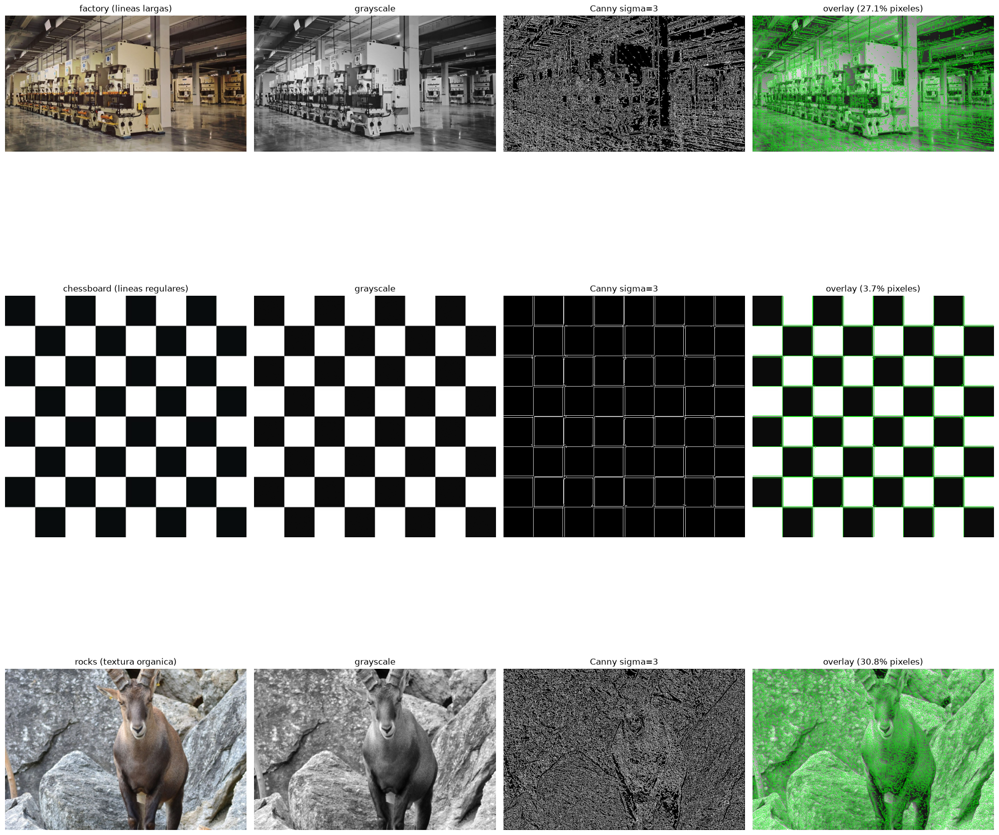

In [26]:
images_c = {
    'factory (lineas largas)':          'data/semana6/factory_a.jpg',
    'chessboard (lineas regulares)':    'data/semana6/chessboard_c.jpg',
    'rocks (textura organica)':         'data/semana6/rocks_c.jpg',
}
BASE = '/home/barajas_angel/repos/TC4033.10_vision_computacional/'

gray_cache = {}
for label, path in images_c.items():
    im = cv2.imread(BASE + path)
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    if gray.shape[1] > 1000:
        scale = 1000 / gray.shape[1]
        gray = cv2.resize(gray, (1000, int(gray.shape[0]*scale)), interpolation=cv2.INTER_AREA)
    gray_cache[label] = (im, gray)

plt.figure(figsize=(20, 22))
for k, (label, (im, gray)) in enumerate(gray_cache.items()):
    fin = canny_from_scratch(gray, 3)[4]
    edge_frac = (fin == 255).mean() * 100

    plt.subplot(3, 4, k*4+1); plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); plt.title(label); plt.axis('off')
    plt.subplot(3, 4, k*4+2); plt.imshow(gray, cmap='gray'); plt.title('grayscale'); plt.axis('off')
    plt.subplot(3, 4, k*4+3); plt.imshow(fin, cmap='gray'); plt.title('Canny sigma=3'); plt.axis('off')
    overlay = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    overlay[fin==255] = [0, 255, 0]
    plt.subplot(3, 4, k*4+4); plt.imshow(overlay); plt.title(f'overlay ({edge_frac:.1f}% pixeles)'); plt.axis('off')
    print(f'{label}: {gray.shape[1]}x{gray.shape[0]}, pixeles de borde = {edge_frac:.2f}%')
plt.tight_layout()
plt.show()

Detalle donde se aprecia el comportamiento del NMS: en el tablero los bordes quedan **finos y localizados** en las intersecciones; en la roca (con el animal) la **densidad de máximos locales es muy alta** y el NMS no puede suprimirlos todos → aparecen **dobles líneas y fragmentos** sobre la textura del pelaje y la superficie rocosa. El tablero (612 px) además es menor, por lo que se muestra a su tamaño real para que los recortes sean comparables en escala.

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


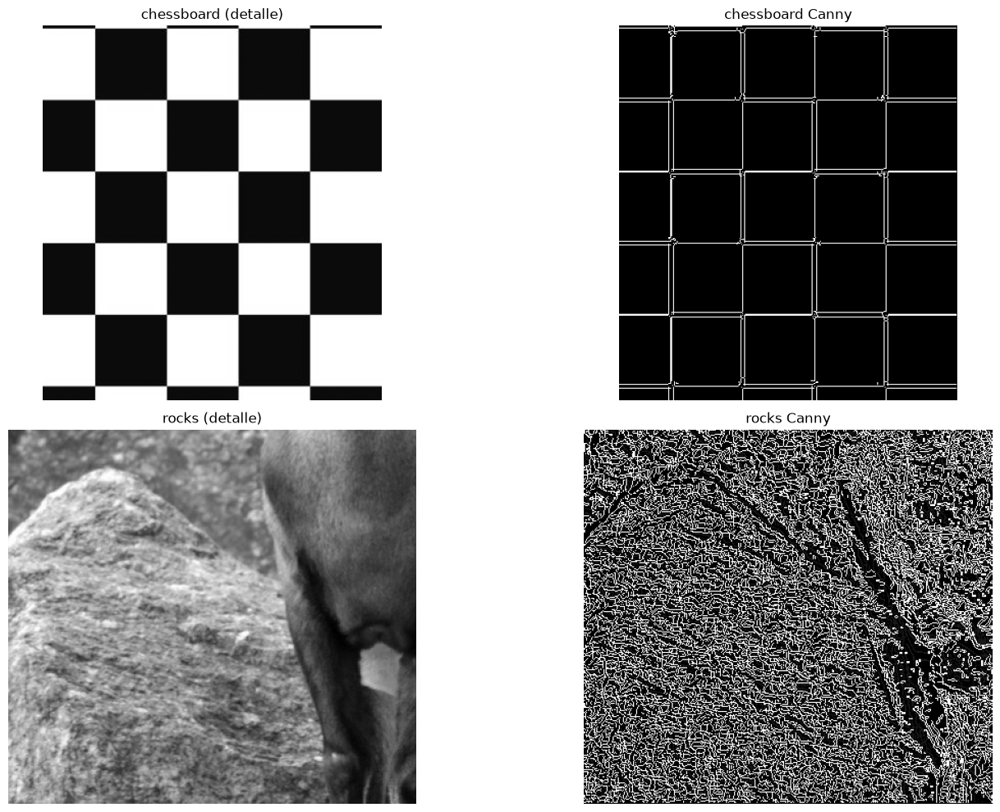

In [27]:
chess = gray_cache['chessboard (lineas regulares)'][1]
rocks = gray_cache['rocks (textura organica)'][1]

chess_fin = canny_from_scratch(chess, 3)[4]
rocks_fin = canny_from_scratch(rocks, 3)[4]

# recortes (r0, r1, c0, c1)
chess_r0, chess_r1, chess_c0, chess_c1 = 150, 550, 250, 650   # intersecciones
rocks_r0, rocks_r1, rocks_c0, rocks_c1 = 300, 700, 200, 600

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0,0].imshow(chess[chess_r0:chess_r1, chess_c0:chess_c1], cmap='gray'); axes[0,0].set_title('chessboard (detalle)'); axes[0,0].axis('off')
axes[0,1].imshow(chess_fin[chess_r0:chess_r1, chess_c0:chess_c1], cmap='gray'); axes[0,1].set_title('chessboard Canny'); axes[0,1].axis('off')
axes[1,0].imshow(rocks[rocks_r0:rocks_r1, rocks_c0:rocks_c1], cmap='gray'); axes[1,0].set_title('rocks (detalle)'); axes[1,0].axis('off')
axes[1,1].imshow(rocks_fin[rocks_r0:rocks_r1, rocks_c0:rocks_c1], cmap='gray'); axes[1,1].set_title('rocks Canny'); axes[1,1].axis('off')
plt.tight_layout()
plt.show()

### c.2) Hallazgos c)

Véanse las conclusiones al final del notebook (sección e).

## Extra — Comparación con el detector optimizado de OpenCV: `cv2.Canny()`

El enunciado pide implementar Canny "usando OpenCV y Python desde los aspectos de bajo nivel". El extra cierra comparando nuestro pipeline desde cero con el detector interno de OpenCV (`cv2.Canny`), que usa los **mismos 5 pasos** pero optimizado (C++/SSE). Parámetros equivalentes:

- Nuestro pipeline: σ=3, doble umbral con ratios 0.05/0.09 sobre el máximo del gradiente.
- `cv2.Canny(gray, threshold1, threshold2)`: umbral bajo ≈ 0.5 × umbral alto (recomendación estándar de las docs de OpenCV).

/tmp/ipykernel_3638878/65442114.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Ix = ndimage.filters.convolve(img, Kx)
/tmp/ipykernel_3638878/65442114.py:6: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  Iy = ndimage.filters.convolve(img, Ky)


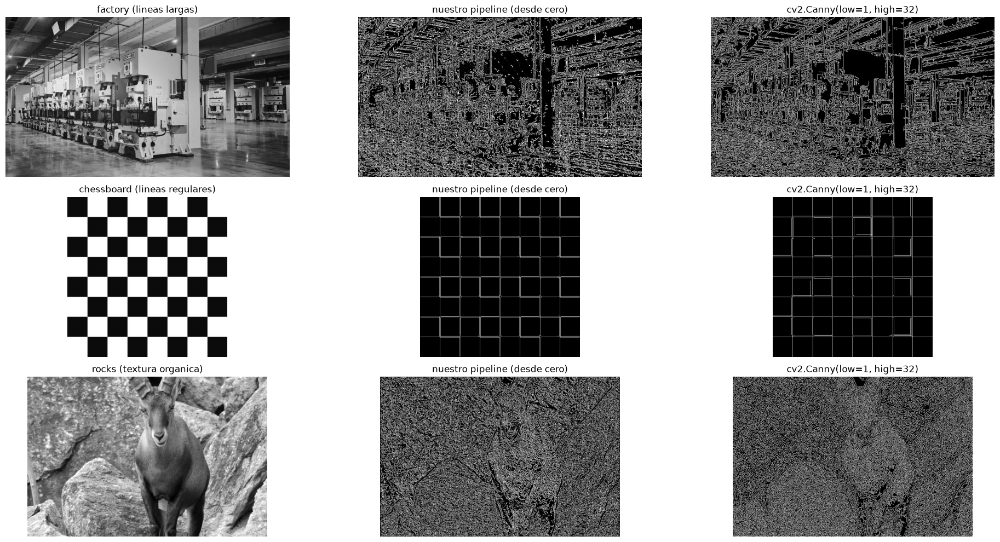

In [28]:
plt.figure(figsize=(20, 10))
for k, (label, (im, gray)) in enumerate(gray_cache.items()):
    # nuestro pipeline desde cero
    ours = canny_from_scratch(gray, 3)[4]
    # cv2.Canny: umbral alto ~ 9% del max de gradiente (misma logica del pipeline)
    g_sm = convolve(gray, gaussian_kernel(3, 3))
    Gmax = np.hypot(ndimage.sobel(g_sm, 1), ndimage.sobel(g_sm, 0)).max()
    high = int(Gmax * 0.09); low = int(high * 0.05)
    cv = cv2.Canny(gray, low, high)

    plt.subplot(3, 3, k*3+1); plt.imshow(gray, cmap='gray'); plt.title(label); plt.axis('off')
    plt.subplot(3, 3, k*3+2); plt.imshow(ours, cmap='gray'); plt.title('nuestro pipeline (desde cero)'); plt.axis('off')
    plt.subplot(3, 3, k*3+3); plt.imshow(cv, cmap='gray'); plt.title(f'cv2.Canny(low={low}, high={high})'); plt.axis('off')
plt.tight_layout()
plt.show()

### Extra — hallazgos

Véanse las conclusiones al final del notebook (sección e).

## e) Conclusiones y hallazgos generales### a) Efecto de σ (imagen industrial, kernel 3×3)| σ | Efecto observado ||---|---|| 1 | Máximo detalle: bordes finos pero **fragmentados**; ruido de superficie y texturas metálicas generan líneas espurias. || 3 | Compensación buena para esta escala: estructura de la maquinaria legible, bordes continuos. || 5 | Las líneas finas (costuras, tornillería) empiezan a desaparecer; quedan las aristas principales. || 10 | Solo los **contornos grandes** de la maquinaria y del piso; la imagen se "dilata" visualmente. || 20 | **Casi todo se pierde**: el suavizado borra el gradiente antes de que el detector lo vea; quedan manchas difusas. |**Interpretación con la teoría (Módulo 3.1, p.20):** el kernel gaussiano de σ=20 en una imagen de 563 px de alto tiene un ancho de ~100 px — más grande que muchos objetos —, por lo que el gradiente máximo cae por debajo del umbral alto. σ debe elegirse **en función de la escala de los bordes esperados**, no de la resolución de la imagen.### b) Con y sin remoción de ruido- Sin suavizado el detector es **hipersensible**: cada variación de 1–2 niveles de gris (compresión JPEG, grano, polvo) aparece como borde. El número de píxeles de borde aumenta y la mayoría son falsos positivos.- Con Gaussiano σ=3 las líneas espurias desaparecen y los bordes reales quedan más finos (el NMS ya no compite con máximos vecinos creados por el ruido).- Con ruido sal y pimienta el caso es extremo: sin suavizado el detector se **satura** (el ruido crea máximos de gradiente enormes); con σ=3 se recupera casi el mismo resultado que la imagen limpia.- Conclusión práctica: **el paso 1 no es opcional** — en imagenología real (JPEG, sensores con ruido) siempre se suaviza antes de derivar; el costo es un ligero desplazamiento/dilatación del borde, controlado por σ.### c) Comportamiento según cantidad de líneas y texturaDensidad de píxeles de borde medida con el pipeline (σ=3), imagen a 1000 px de ancho:| Imagen | Píxeles de borde | Estructura dominante ||---|---|---|| Chessboard (612 px) | **3.69 %** | líneas regulares, alto contraste, pocas intersecciones || Fábrica | **27.08 %** | líneas largas y paralelas de la maquinaria || Roca + animal | **30.84 %** | textura orgánica de alta frecuencia (pelaje, roca) |- **Chessboard (líneas regulares, alto contraste):** caso ideal del detector: bordes **finos, localizados y estables**, con la densidad de borde más baja de las tres (3.69 %). Las intersecciones se resuelven bien porque los máximos de gradiente están claramente separados en las dos direcciones. Por esta combinación (contraste + repetibilidad + localización) es el patrón que se usa para **calibrar cámaras**.- **Fábrica (líneas largas, baja densidad de intersecciones):** el NMS trabaja a su favor — máximos bien separados → bordes finos y limpios, pocas ambigüedades. Es el caso donde la relación señal/ruido del detector es mejor.- **Roca + animal (textura orgánica, alta densidad):** el caso hostil, y los datos lo confirman: **30.84 %** de la imagen sale marcada como borde, incluso más que la fábrica (27.08 %), y el overlay muestra **cobertura casi continua** en lugar de líneas discretas: el NMS no puede suprimir máximos locales tan juntos (pelaje, granito) y aparecen **dobles líneas y fragmentos**. Conclusión importante: **Canny no distingue "estructura" de "textura"** — todo gradiente fuerte es un candidato a borde, y el parámetro que realmente gobierna el resultado en este caso es el **umbral alto**, no σ. Aquí es donde los métodos de alto nivel (keypoints, Módulo 3.1/3.2) toman el relevo: no importan todos los bordes, sino los **puntos estables y descriptivos**.### Extra — vs `cv2.Canny`- Los mapas de borde son **prácticamente idénticos** (mismos 5 pasos; pequeñas diferencias por la forma exacta de calcular gradiente/NMS en C++ de OpenCV y por el tipo de dato).- `cv2.Canny` es **órdenes de magnitud más rápido** en CPU (no importa a escala de clase, pero sí en producción embebida, p.ej. Jetson para el proyecto BSKLab).- Validación cruzada: los ratios de umbral usados (0.05/0.09 del máximo del gradiente) se corresponden con la recomendación estándar de OpenCV (bajo ≈ 0.5 × alto, docs opencv.org/da/d22).### Conclusión generalEl detector de Canny es un **filtro de escala + umbral**: su desempeño está gobernado por (1) la elección de σ relativa a la escala de los bordes de interés y (2) el par de umbrales que controla el equilibrio sensibilidad–falsos-positivos. Funciona excepcionalmente en imágenes estructuradas (maquinaria, patrones de calibración) y se degrada en texturas de alta frecuencia, donde el concepto de "borde" pierde sentido y conviene pasar al nivel de keypoints/descriptores (Harris, SIFT) que vimos en esta misma semana.### Referencias- Canny, J. (1986). A computational approach to edge detection. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 8*(6), 679–714.- González, R., & Woods, R. (2008). *Digital Image Processing* (4ª ed.). Pearson. Capítulo 9.- OpenCV documentation. (s.f.). *Canny Edge Detection*. https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html- Ochoa Ruiz, G. (s.f.). *Módulo 3.1 — Detección de puntos de interés* [Material de curso]. Tecnologico de Monterrey.- Ochoa Ruiz, G. (s.f.). *Módulo 3.2 — Extracción de descriptores* [Material de curso]. Tecnologico de Monterrey.- pyImageSearch. (2021). *OpenCV Edge Detection (cv2.Canny)*. https://pyimagesearch.com/2021/05/12/opencv-edge-detection-cv2-canny